# Module 3: Fraud Detection

**Business question:** NovaFin processes thousands of transactions a day. How do we catch fraud while keeping unnecessary investigations low?

**Chain:** transaction data → fraud probability (supervised) and anomaly score (unsupervised) → expected operational cost → alert threshold → investigation policy.

**What you will learn:** severe class imbalance, why accuracy misleads, PR curves, Isolation Forest, and picking a threshold by **cost**, not by 0.5.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, subprocess, importlib.util
if importlib.util.find_spec("google.colab"):             # Colab: install the extra libraries once
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "xgboost", "lightgbm", "imbalanced-learn"])
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
try:
    from google.colab import drive; drive.mount("/content/drive")
except ImportError:
    pass
CANDIDATES = [Path("/content/drive/MyDrive/NovaFin_Capstone/data"), Path("../../Project"), Path("/mnt/project-files/Project")]
DATA = next(p for p in CANDIDATES if (p / "nova_transactions.csv").exists())
OUT = DATA.parent / "outputs" if "drive" in str(DATA) else Path("../outputs")
OUT.mkdir(exist_ok=True, parents=True)
SEED = 42
sns.set_theme(style="whitegrid", palette="deep")

## 1. Load and inspect
We sort by time: fraud models must be tested on **later** transactions than they were trained on, as in real life.

In [2]:
df = pd.read_csv(DATA / "nova_transactions.csv", parse_dates=["Timestamp"]).sort_values("Timestamp").reset_index(drop=True)
print(df.shape, "| missing:", df.isna().sum().sum())
print("Period:", df.Timestamp.min().date(), "to", df.Timestamp.max().date())
print(f"Fraud rate: {df.Fraud_Flag.mean():.2%}  ({df.Fraud_Flag.sum()} frauds)")
df.head()

(30000, 12) | missing: 0
Period: 2025-01-01 to 2026-08-31
Fraud rate: 2.28%  (684 frauds)


,Transaction_ID,Customer_ID,Timestamp,Amount,Transaction_Type,Merchant_Category,Location,Device_ID,Account_Age_Months,Historical_Avg_Transaction,Transaction_Frequency,Fraud_Flag
0,5000001,200541,2025-01-01 00:00:00.000000000,2582.90,Payment,Retail,Chennai,11437,77,4650.19,8,0
1,5000002,201166,2025-01-01 00:29:08.218273942,1236.10,Payment,Travel,Pune,10504,170,9832.22,10,0
2,5000003,200479,2025-01-01 00:58:16.436547884,7909.31,Transfer,Investment,Hyderabad,11361,67,5655.09,8,0
3,5000004,201405,2025-01-01 01:27:24.654821827,41417.90,Transfer,Retail,Mumbai,10944,133,8045.82,9,0
4,5000005,202330,2025-01-01 01:56:32.873095769,10893.53,Withdrawal,Utilities,Kolkata,11100,62,13553.16,5,0


**Why accuracy is useless here:** a model that calls *every* transaction genuine is 97.7% accurate and catches zero fraud. We use recall (share of frauds caught), precision (share of alerts that are real fraud) and PR-AUC.

## 2. Exploratory analysis
The brief asks for fraud rate by transaction type, amount, location and customer behaviour.

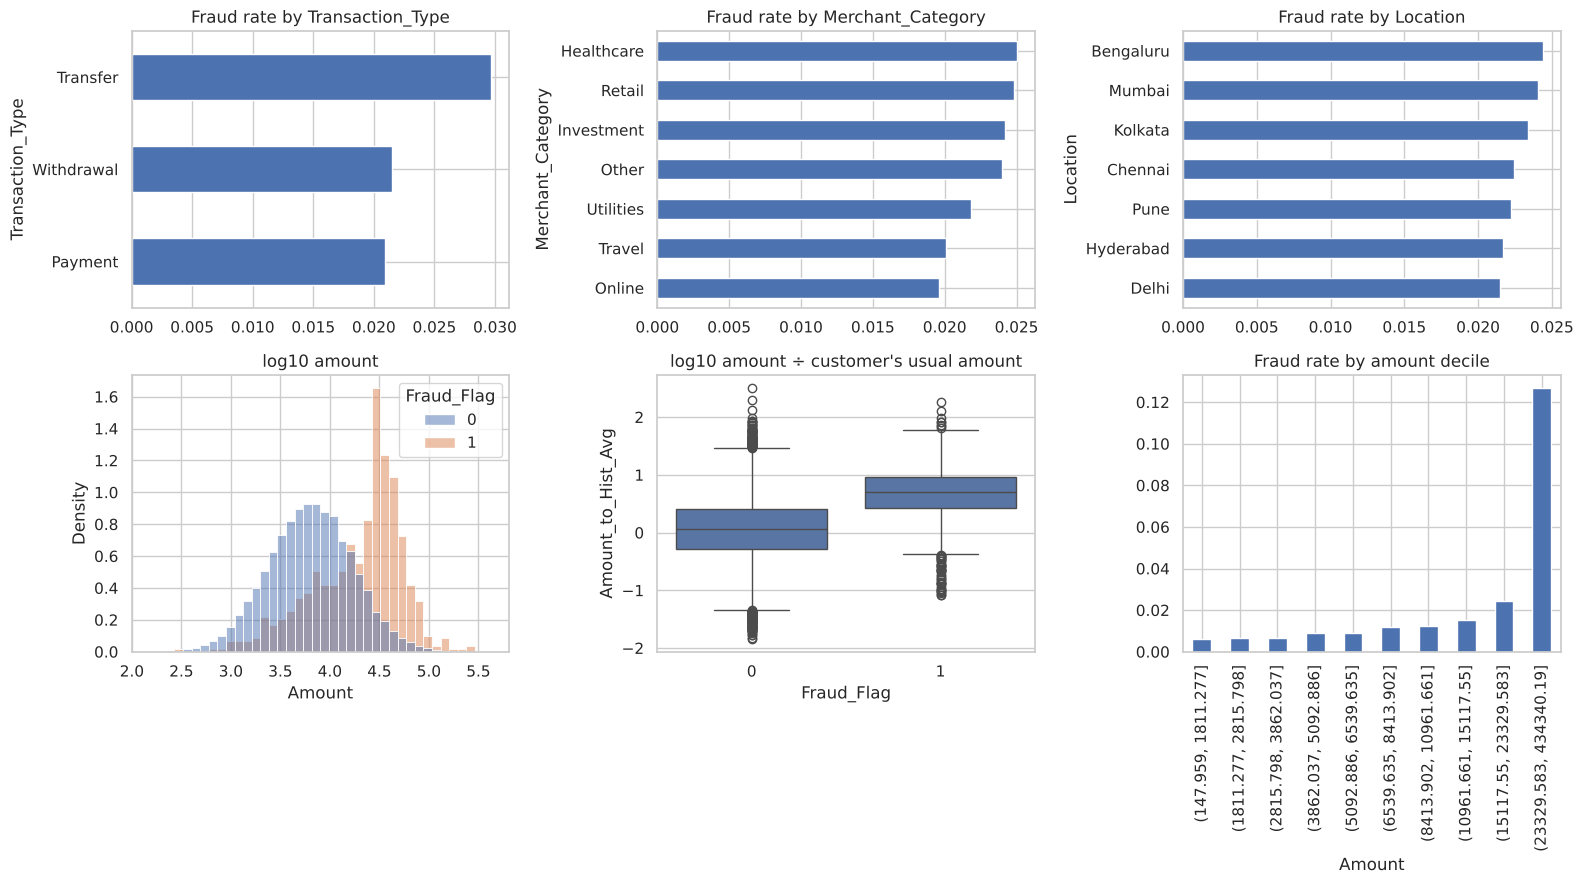

In [3]:
df["Amount_to_Hist_Avg"] = df["Amount"] / df["Historical_Avg_Transaction"]
df["Hour"] = df["Timestamp"].dt.hour
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, col in zip(ax[0], ["Transaction_Type", "Merchant_Category", "Location"]):
    df.groupby(col)["Fraud_Flag"].mean().sort_values().plot.barh(ax=a, title=f"Fraud rate by {col}")
sns.histplot(data=df, x=np.log10(df["Amount"]), hue="Fraud_Flag", stat="density", common_norm=False, bins=40, ax=ax[1, 0]).set_title("log10 amount")
sns.boxplot(data=df, x="Fraud_Flag", y=np.log10(df["Amount_to_Hist_Avg"]), ax=ax[1, 1]).set_title("log10 amount ÷ customer's usual amount")
amt_band = pd.qcut(df["Amount"], 10)
df.groupby(amt_band, observed=True)["Fraud_Flag"].mean().plot.bar(ax=ax[1, 2], title="Fraud rate by amount decile", rot=90)
plt.tight_layout(); plt.show()

In [4]:
df.groupby("Fraud_Flag")[["Amount", "Amount_to_Hist_Avg", "Account_Age_Months", "Transaction_Frequency", "Hour"]].median().round(2)

,Amount,Amount_to_Hist_Avg,Account_Age_Months,Transaction_Frequency,Hour
Fraud_Flag,,,,,
0,6411.09,1.17,90.0,9.0,11.0
1,26438.00,5.00,93.0,9.0,12.0


**What the EDA says:** type, merchant and city barely change the fraud rate (all ~2–3%). The strong signal is **behavioural**: fraudulent transactions are about 4× larger than normal and about 5× the customer's usual amount. Fraud rate climbs sharply in the top amount deciles.

## 3. Features and time-based split
Features: amount (raw and log), amount ÷ customer's historical average, hour, account age, transaction frequency, and one-hot type, merchant and city. We drop IDs and `Device_ID` (a label, not a number).

Split by time: first 60% **train**, next 20% **validation** (to choose the threshold), last 20% **test** (to report results honestly).

In [5]:
X = df.drop(columns=["Transaction_ID", "Customer_ID", "Timestamp", "Device_ID", "Fraud_Flag"]).copy()
X["Log_Amount"] = np.log1p(X["Amount"])
X = pd.get_dummies(X, columns=["Transaction_Type", "Merchant_Category", "Location"], dtype=float)
y = df["Fraud_Flag"]
n = len(df); i1, i2 = int(n * 0.6), int(n * 0.8)
X_tr, y_tr, X_va, y_va, X_te, y_te = X[:i1], y[:i1], X[i1:i2], y[i1:i2], X[i2:], y[i2:]
print("Train / validation / test frauds:", y_tr.sum(), y_va.sum(), y_te.sum())

Train / validation / test frauds: 411 129 144


## 4. Supervised models
Imbalance handling: `class_weight="balanced"` (logistic, random forest), `scale_pos_weight` (XGBoost), and SMOTE (synthetic minority oversampling, applied to **training data only**).

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from xgboost import XGBClassifier
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

spw = (y_tr == 0).sum() / (y_tr == 1).sum()
models = {
    "Logistic (balanced)": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    "Logistic + SMOTE": imb_pipeline(StandardScaler(), SMOTE(random_state=SEED), LogisticRegression(max_iter=2000)),
    "Random forest (balanced)": RandomForestClassifier(n_estimators=400, min_samples_leaf=10, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, random_state=SEED, verbosity=0),
}
rows, p_va, p_te = [], {}, {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p_va[name], p_te[name] = m.predict_proba(X_va)[:, 1], m.predict_proba(X_te)[:, 1]
    rows.append([name, roc_auc_score(y_te, p_te[name]), average_precision_score(y_te, p_te[name])])
res = pd.DataFrame(rows, columns=["Model", "ROC-AUC (test)", "PR-AUC (test)"]).set_index("Model").round(3)
res

,ROC-AUC (test),PR-AUC (test)
Model,,
Logistic (balanced),0.794,0.105
Logistic + SMOTE,0.793,0.104
Random forest (balanced),0.792,0.125
XGBoost,0.790,0.117


**PR-AUC baseline:** a random model scores PR-AUC equal to the fraud rate (~0.02), so 0.10+ means the model concentrates fraud about 5× better than chance.

## 5. Unsupervised detection: Isolation Forest
Isolation Forest never sees `Fraud_Flag`. It flags points that are easy to isolate, meaning unusual ones. We set `contamination` to the fraud rate (2.3%) and train on the training period.

In [7]:
iso = make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, contamination=0.023, random_state=SEED)).fit(X_tr)
iso_va, iso_te = -iso.score_samples(X_va), -iso.score_samples(X_te)     # higher = more anomalous
iso_flag = iso.predict(X_te) == -1
best_name = res["PR-AUC (test)"].idxmax()
sup_flag = p_te[best_name] >= np.quantile(p_va[best_name], 1 - 0.023)   # same alert volume as Isolation Forest
def rate(flag):
    tp = (flag & (y_te == 1)).sum()
    return pd.Series({"alerts": flag.sum(), "frauds caught": tp, "recall": tp / y_te.sum(), "precision": tp / max(flag.sum(), 1)})
compare = pd.DataFrame({f"Supervised ({best_name})": rate(sup_flag), "Isolation Forest": rate(iso_flag)}).T
compare["ROC-AUC"] = [roc_auc_score(y_te, p_te[best_name]), roc_auc_score(y_te, iso_te)]
compare.round(3)

,alerts,frauds caught,recall,precision,ROC-AUC
Supervised (Random forest (balanced)),133.0,24.0,0.167,0.180,0.792
Isolation Forest,134.0,18.0,0.125,0.134,0.717


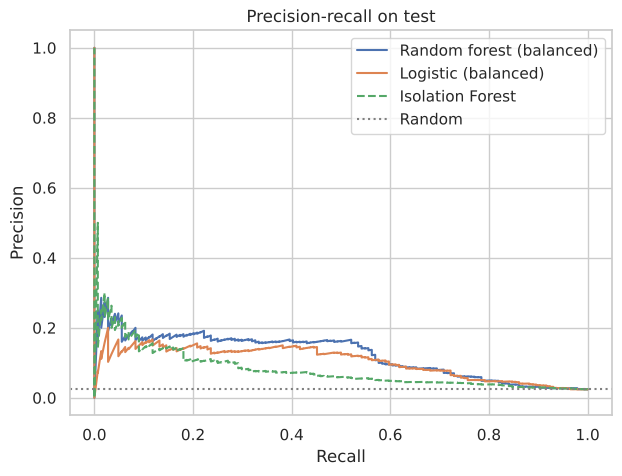

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for name in [best_name, "Logistic (balanced)"]:
    pr, rc, _ = precision_recall_curve(y_te, p_te[name]); ax.plot(rc, pr, label=name)
pr, rc, _ = precision_recall_curve(y_te, iso_te); ax.plot(rc, pr, label="Isolation Forest", ls="--")
ax.axhline(y_te.mean(), c="grey", ls=":", label="Random"); ax.set(xlabel="Recall", ylabel="Precision", title="Precision-recall on test"); ax.legend(); plt.show()

**Supervised vs anomaly detection:** the supervised model wins because it learns what *past* fraud looked like. Isolation Forest still catches several times more fraud than random, without any labels. It is useful for **new fraud patterns** the labels have not seen yet. Best practice: use the supervised score for alerts and the anomaly score as a second line.

## 6. Cost-based threshold
Missed fraud costs **₹10,000**; investigating a false alarm costs **₹500**. A missed fraud is 20× worse.

**Theory:** if the probability p is *calibrated*, investigate when expected loss from missing it exceeds the investigation cost: p × 10,000 > (1 − p) × 500, i.e. **p > 500 / 10,500 ≈ 0.048**. But our models use class weights, which inflate probabilities, so their scores are not true probabilities. That is why we search for the threshold on validation data instead of trusting a formula.

We pick the threshold on the **validation** set, then apply it unchanged to the **test** set. Choosing it on test would be cheating.

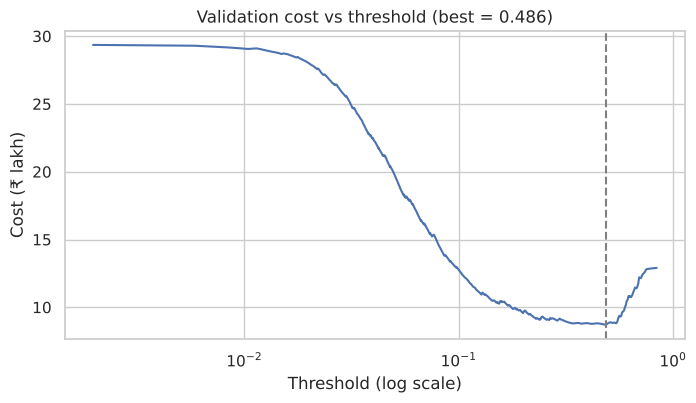

In [9]:
COST_FN, COST_FP = 10_000, 500
def cost(y_true, p, t):
    y_true = np.asarray(y_true)
    return COST_FN * ((p < t) & (y_true == 1)).sum() + COST_FP * ((p >= t) & (y_true == 0)).sum()
grid = np.unique(np.quantile(p_va[best_name], np.linspace(0, 1, 501)))
val_costs = np.array([cost(y_va, p_va[best_name], t) for t in grid])
t_star = grid[val_costs.argmin()]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, val_costs / 1e5); ax.axvline(t_star, ls="--", c="grey"); ax.set(xscale="log", xlabel="Threshold (log scale)", ylabel="Cost (₹ lakh)", title=f"Validation cost vs threshold (best = {t_star:.3f})"); plt.show()

**Check the theory with an unweighted (calibrated) logistic model:** its cost-optimal threshold should land near 0.048.

In [10]:
lr_cal = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_tr, y_tr)
pc_va = lr_cal.predict_proba(X_va)[:, 1]
g2 = np.unique(np.quantile(pc_va, np.linspace(0, 1, 501)))
print("Calibrated logistic: cost-optimal threshold on validation =", round(g2[np.argmin([cost(y_va, pc_va, t) for t in g2])], 3), "(theory: 0.048)")

Calibrated logistic: cost-optimal threshold on validation = 0.059 (theory: 0.048)


In [11]:
def summary(t, label):
    p = p_te[best_name]; flag = p >= t; yt = np.asarray(y_te)
    return pd.Series({"threshold": t, "alerts": flag.sum(), "frauds caught": (flag & (yt == 1)).sum(), "frauds missed": (~flag & (yt == 1)).sum(),
                      "false alarms": (flag & (yt == 0)).sum(), "cost ₹": cost(y_te, p, t)}, name=label)
no_model = pd.Series({"threshold": np.nan, "alerts": 0, "frauds caught": 0, "frauds missed": y_te.sum(), "false alarms": 0, "cost ₹": COST_FN * y_te.sum()}, name="No model (miss all)")
review_all = pd.Series({"threshold": 0, "alerts": len(y_te), "frauds caught": y_te.sum(), "frauds missed": 0, "false alarms": (y_te == 0).sum(), "cost ₹": COST_FP * (y_te == 0).sum()}, name="Investigate everything")
cost_table = pd.DataFrame([no_model, review_all, summary(0.5, "Default threshold 0.5"), summary(t_star, "Cost-optimal threshold")])
cost_table["saving vs no model ₹"] = cost_table.loc["No model (miss all)", "cost ₹"] - cost_table["cost ₹"]
cost_table

,threshold,alerts,frauds caught,frauds missed,false alarms,cost ₹,saving vs no model ₹
No model (miss all),NaN,0.0,0.0,144.0,0.0,1440000.0,0.0
Investigate everything,0.00000,6000.0,144.0,0.0,5856.0,2928000.0,-1488000.0
Default threshold 0.5,0.50000,410.0,67.0,77.0,343.0,941500.0,498500.0
Cost-optimal threshold,0.48597,420.0,68.0,76.0,352.0,936000.0,504000.0


## 7. Business result
The test period is the last 20% of 20 months (~4 months). We scale the saving to one year and to every 1,000 transactions.

In [12]:
months_test = (df.Timestamp.iloc[i2:].max() - df.Timestamp.iloc[i2:].min()).days / 30.4
best_row = cost_table.loc["Cost-optimal threshold"]
saving_per_1000 = best_row["saving vs no model ₹"] / len(y_te) * 1000
annual_saving = best_row["saving vs no model ₹"] / months_test * 12
print(f"Test months ≈ {months_test:.1f}")
print(f"Saving per 1,000 transactions: ₹{saving_per_1000:,.0f}")
print(f"Annual saving at this dataset's volume: ₹{annual_saving/1e5:,.1f} lakh")
print(f"Cost reduction vs no model: {best_row['saving vs no model ₹']/cost_table.loc['No model (miss all)','cost ₹']:.0%}")

Test months ≈ 4.0
Saving per 1,000 transactions: ₹84,000
Annual saving at this dataset's volume: ₹15.2 lakh
Cost reduction vs no model: 35%


## 8. Explainability

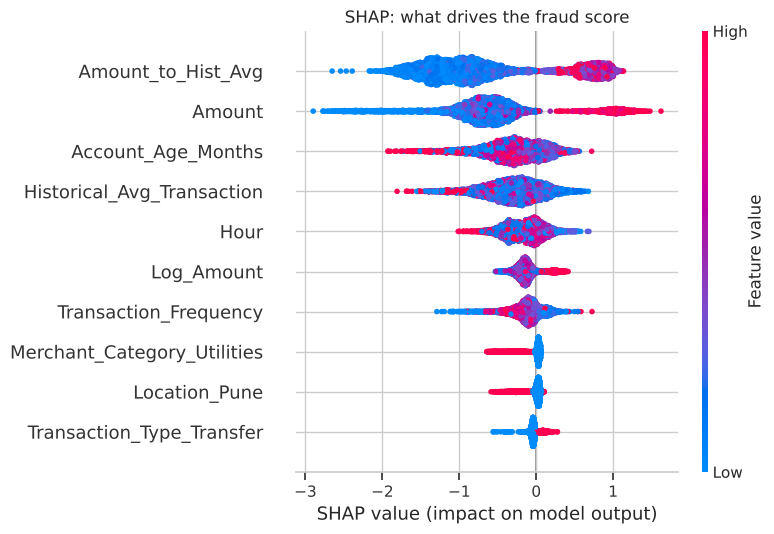

In [13]:
import shap
xgb = models["XGBoost"]
sv = shap.TreeExplainer(xgb).shap_values(X_te)
shap.summary_plot(sv, X_te, max_display=10, show=False); plt.title("SHAP: what drives the fraud score"); plt.tight_layout(); plt.show()

## 9. Save outputs

In [14]:
pd.DataFrame({"Transaction_ID": df.Transaction_ID.iloc[i2:].values, "Fraud_Prob": p_te[best_name], "Anomaly_Score": iso_te,
              "Alert": p_te[best_name] >= t_star, "Fraud_Flag": y_te.values}).round(5).to_csv(OUT / "m3_test_alerts.csv", index=False)
pd.Series({"model": best_name, "threshold": t_star, "saving_per_1000_txn_inr": saving_per_1000, "annual_saving_inr": annual_saving,
           "cost_reduction_pct": best_row["saving vs no model ₹"] / cost_table.loc["No model (miss all)", "cost ₹"],
           "recall": best_row["frauds caught"] / y_te.sum(), "alerts_share": best_row["alerts"] / len(y_te)}).to_csv(OUT / "m3_summary.csv")
print("Saved")

Saved


## 10. Conclusions
1. Fraud is driven by **behaviour** (amount vs the customer's normal), not by type, merchant or city.
2. Supervised models beat Isolation Forest; anomaly detection is still worth keeping as a second line for new fraud patterns.
3. Because a missed fraud costs 20× a false alarm, the right cut-off on a *true* probability is about 5%, not 50%. Class-weighted models already shift their scores, which is why the threshold must be tuned on validation data with the real costs.
4. The cost-optimal policy cuts expected fraud-related cost by about a third versus no model, while investigating only about 7% of transactions.
5. **Recommendation:** deploy the supervised score with the cost-optimal threshold, re-tune the threshold monthly as costs and fraud rates change, and invest in richer behavioural data (device history, velocity) to lift precision.
6. **Limits:** weak signal (PR-AUC ~0.1), synthetic data, fixed investigation costs; the saving scales with real transaction volume.